# SegFormer-B2 trên Kaggle: Kvasir-SEG → CVC-ClinicDB

**Trước khi chạy** (panel bên phải):
1. *Add Input* 3 dataset:
   - Dataset code (vd. `medseg-code` hay `segformer`, tên nào cũng được): upload `Kaggle/medseg-code.zip` của repo (code, splits, `pretrained/mit_b2.pth`).
   - Kvasir-SEG, ví dụ `debeshjha1/kvasirseg`.
   - CVC-ClinicDB, ví dụ `balraj98/cvcclinicdb`.

   Notebook tự tìm thư mục ảnh/mặt nạ bằng cách khớp tên file với `data/splits/*/all.txt`, nên bản nào trên Kaggle cũng dùng được, miễn đủ 1000 + 612 mẫu.
2. *Accelerator*: **GPU T4** (code chạy 1 GPU). *Internet*: **On** (để `pip install albumentations`).

**Lần đầu** để `MAX_ITERS = 200` và chạy tương tác để đo `s/it`. Train đủ thì đổi thành `None` rồi *Save Version → Save & Run All*.

**Phiên Kaggle tối đa 12 giờ.** 160k iter có thể vượt mức này. Sau `TIME_LIMIT_H` giờ notebook tự dừng train ngay sau một checkpoint (giữ `latest.pth`) rồi chạy tiếp các ô kết quả/dọn dẹp, để version kết thúc bình thường và lưu output. Khi đó *Add Input* output của version trước (notebook này) và để `RESUME = "auto"` để train tiếp từ `latest.pth`.

In [7]:
DATASET = "kvasir_seg"     # "kvasir_seg": E1 + E2 (test Kvasir + chuyển miền CVC) | "cvc_clinicdb": E3
MAX_ITERS = 200           # None = 160000 iter như cấu hình gốc; 200 = chạy thử để đo tốc độ
BATCH_SIZE = None          # None = 16 như cấu hình gốc
RESUME = "auto"            # "auto": tìm latest.pth trong input (output version trước); None: train từ đầu
DELETE_ITER_CKPTS = True   # cuối phiên xóa iter_*.pth (~330 MB/file), giữ latest.pth và best.pth
TIME_LIMIT_H = 11.0        # quá mốc này (tính từ ô Môi trường) thì dừng train ở checkpoint kế tiếp; phiên Kaggle tối đa 12 giờ

## 1. Môi trường

In [8]:
import csv, glob, hashlib, json, os, re, shutil, subprocess, sys, time, zipfile
from pathlib import Path

T0 = time.time()  # mốc tính TIME_LIMIT_H

INPUT, ROOT = Path("/kaggle/input"), Path("/kaggle/working/image_segmentation")

def find_code_dir() -> Path:
    """Thư mục gói code trong input: có src/medseg/__init__.py và configs/config.json.

    - Bỏ output của version trước (bản copy nằm trong .../image_segmentation/).
    - Không bắt buộc dataset-metadata.json: upload bằng Kaggle CLI thì file này thành metadata, không nằm trong dataset.
    - Gói còn nguyên .zip (Kaggle không giải nén) thì giải nén ra /tmp/medseg-code.
    """
    def scan(base: Path) -> list[Path]:
        hits = {Path(p).parents[2].resolve() for p in glob.glob(f"{base}/**/src/medseg/__init__.py", recursive=True)}
        return sorted(h for h in hits if (h / "configs/config.json").exists() and "image_segmentation" not in h.parts)

    hits = scan(INPUT)
    if not hits:
        for z in sorted(glob.glob(f"{INPUT}/**/*.zip", recursive=True)):
            with zipfile.ZipFile(z) as zf:
                if any(n.endswith("src/medseg/__init__.py") for n in zf.namelist()):
                    out = Path("/tmp/medseg-code")
                    shutil.rmtree(out, ignore_errors=True)
                    zf.extractall(out)
                    print("giải nén gói code:", z, "->", out)
                    hits = scan(out)
                    break
    if len(hits) > 1:
        with_meta = [h for h in hits if (h / "dataset-metadata.json").exists()]
        if len(with_meta) != 1:
            raise AssertionError(f"Thấy {len(hits)} gói code trong input, chỉ Add Input một gói: {hits}")
        hits = with_meta
    if not hits:
        print("Các thư mục đang có trong /kaggle/input:")
        for root, dirs, _ in os.walk(INPUT, followlinks=True):
            depth = len(Path(root).relative_to(INPUT).parts)
            if depth >= 4:
                dirs[:] = []
                continue
            print("  " * depth + (Path(root).name or str(INPUT)) + "/")
        raise AssertionError("Không thấy gói code (thư mục có src/medseg/ và configs/config.json) trong /kaggle/input. "
                             "Add Input dataset chứa Kaggle/medseg-code.zip (tạo bằng scripts/build_kaggle.py).")
    return hits[0]


CODE = find_code_dir()
if not ROOT.exists():
    shutil.copytree(CODE, ROOT, ignore=shutil.ignore_patterns("dataset-metadata.json"))
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("code:", CODE, "->", ROOT)

import importlib.metadata as md
def version(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None
need = [p for p, v in {"albumentations": "2.0.8", "tifffile": None}.items()
        if version(p) is None or (v and version(p) != v)]
if need:
    pins = {"albumentations": "albumentations==2.0.8"}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *[pins.get(p, p) for p in need]], check=True)

import torch, albumentations
print("torch", torch.__version__, "| albumentations", albumentations.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ (bật Accelerator GPU)")

code: /kaggle/input/datasets/daisy2812/segformer-data -> /kaggle/working/image_segmentation
torch 2.11.0+cu130 | albumentations 2.0.8
GPU: Tesla T4


## 2. Dữ liệu: tìm Kvasir-SEG / CVC-ClinicDB trong input → `data/raw/` → `prepare_data.py`

Mẫu được copy đúng theo tên trong `data/splits/<dataset>/all.txt`, vào đúng đường dẫn trong `configs/datasets.yaml`, rồi chuẩn hóa về 256 × 256 như trên máy. Cuối bước này notebook so manifest mới với manifest của nhóm (SHA-256 file gốc, kích thước, tỷ lệ tổn thương sau resize) để xác nhận dữ liệu giống hệt.

In [9]:
from medseg.config import load_data_config, load_dataset_specs
from medseg.data.io import IMAGE_EXTS
from medseg.data.splits import load_split
from medseg.paths import from_root

DATASETS = ("kvasir_seg", "cvc_clinicdb")
MASK_WORDS = ("mask", "ground", "gt", "label", "annot")
SIZE = load_data_config()["image_size"]
specs = load_dataset_specs()
meta_dir, ref_dir = ROOT / "data/metadata", ROOT / "data/metadata/reference"


def index_input() -> dict:
    """{(thư mục, đuôi): tập tên file} cho mọi thư mục ảnh trong /kaggle/input."""
    found = {}
    for root, _, files in os.walk(INPUT, followlinks=True):
        if "/data/processed/" in root + "/" or "/data/raw/" in root + "/":
            continue  # bỏ dữ liệu trong output của version trước
        by_ext = {}
        for f in files:
            stem, ext = os.path.splitext(f)
            if ext.lower() in IMAGE_EXTS:
                by_ext.setdefault(ext.lower(), set()).add(stem)
        for ext, stems in by_ext.items():
            found[(Path(root), ext)] = stems
    return found


def reference_ext(dataset: str, column: str) -> str:
    with open(meta_dir / f"{dataset}_manifest.csv", encoding="utf-8") as f:
        return Path(next(csv.DictReader(f))[column]).suffix.lower()


def ref_sha(dataset: str, column: str, k: int = 5) -> dict:
    """SHA-256 file gốc của k mẫu đầu trong manifest của nhóm, để chọn đúng thư mục khi có nhiều ứng viên."""
    with open(ref_dir / f"{dataset}_manifest.csv", encoding="utf-8") as f:
        rows = sorted(csv.DictReader(f), key=lambda r: r["name"])[:k]
    return {r["name"]: r[column] for r in rows}


def sha_misses(cand, ref: dict) -> int:
    d, ext = cand
    return sum(hashlib.sha256((d / f"{n}{ext}").read_bytes()).hexdigest() != h for n, h in ref.items())


def locate(dataset: str, found: dict):
    names = set(load_split(dataset, "all"))
    cands = [k for k, stems in found.items() if names <= stems]
    is_mask = lambda d: any(w in d.name.lower() for w in MASK_WORDS)
    imgs = [c for c in cands if not is_mask(c[0])]
    msks = [c for c in cands if is_mask(c[0])]
    if not imgs or not msks:
        raise FileNotFoundError(f"{dataset}: không thấy thư mục ảnh + mặt nạ chứa đủ {len(names)} mẫu. "
                                "Kiểm tra đã Add Input đúng dataset chưa.")
    # ưu tiên thư mục có file trùng SHA-256 manifest, rồi đúng định dạng gốc (JPG cho Kvasir, TIFF cho CVC);
    # tránh thư mục ảnh minh họa (vd. Kvasir-SEG/annotated_images = ảnh vẽ khung, KHÔNG phải mặt nạ)
    overlay = lambda d: any(w in d.name.lower() for w in ("annotated", "overlay", "bbox", "vis"))
    sha_img, sha_msk = ref_sha(dataset, "sha256_image"), ref_sha(dataset, "sha256_mask")
    img = min(imgs, key=lambda c: (sha_misses(c, sha_img), overlay(c[0]), c[1] != reference_ext(dataset, "raw_image"), str(c[0])))
    msk = min(msks, key=lambda c: (sha_misses(c, sha_msk), overlay(c[0]), c[1] != reference_ext(dataset, "raw_mask"),
                                   c[0].parent != img[0].parent, str(c[0])))
    return sorted(names), img, msk


def processed_ok(dataset: str) -> bool:
    d = ROOT / "data/processed" / dataset / str(SIZE)
    n = len(load_split(dataset, "all"))
    return all((d / sub).is_dir() and len(list((d / sub).glob("*.png"))) == n for sub in ("images", "masks"))


todo = [ds for ds in DATASETS if not processed_ok(ds)]
if todo:
    found = index_input()
    ref_dir.mkdir(exist_ok=True)
    for ds in todo:
        if not (ref_dir / f"{ds}_manifest.csv").exists():
            shutil.copy2(meta_dir / f"{ds}_manifest.csv", ref_dir / f"{ds}_manifest.csv")
        names, (img_dir, img_ext), (msk_dir, msk_ext) = locate(ds, found)
        for (src, ext), key in (((img_dir, img_ext), "raw_images"), ((msk_dir, msk_ext), "raw_masks")):
            dst = from_root(specs[ds][key])
            dst.mkdir(parents=True, exist_ok=True)
            for n in names:
                shutil.copy2(src / f"{n}{ext}", dst / f"{n}{ext}")
        print(f"[{ds}] {len(names)} mẫu\n  ảnh:    {img_dir} ({img_ext})\n  mặt nạ: {msk_dir} ({msk_ext})")
    subprocess.run([sys.executable, "scripts/prepare_data.py", "--datasets", *todo], check=True)
    shutil.rmtree(ROOT / "data/raw", ignore_errors=True)  # chỉ cần data/processed để train

for ds in DATASETS:
    assert processed_ok(ds), f"{ds}: data/processed chưa đủ mẫu"
    if not (ref_dir / f"{ds}_manifest.csv").exists():
        continue
    read = lambda p: {r["name"]: r for r in csv.DictReader(open(p, encoding="utf-8"))}
    ref, new = read(ref_dir / f"{ds}_manifest.csv"), read(meta_dir / f"{ds}_manifest.csv")
    same_img = sum(ref[n]["sha256_image"] == new[n]["sha256_image"] for n in ref)
    same_msk = sum(ref[n]["sha256_mask"] == new[n]["sha256_mask"] for n in ref)
    same_data = sum(all(ref[n][k] == new[n][k] for k in ("orig_height", "orig_width", "fg_ratio_256", "n_components")) for n in ref)
    # cho phép lệch nhỏ (bản Kaggle nén lại JPG/PNG), nhưng dừng hẳn nếu mặt nạ sai (vd. lấy nhầm thư mục)
    close_fg = sum(abs(float(ref[n]["fg_ratio_256"]) - float(new[n]["fg_ratio_256"])) <= 0.01 for n in ref)
    flag = "OK" if same_data == len(ref) else "CẢNH BÁO: dữ liệu khác bản của nhóm"
    print(f"[{ds}] SHA-256 file gốc trùng: ảnh {same_img}/{len(ref)}, mặt nạ {same_msk}/{len(ref)}; "
          f"{same_data}/{len(ref)} mẫu trùng kích thước + tỷ lệ tổn thương, "
          f"{close_fg}/{len(ref)} mẫu lệch tỷ lệ tổn thương ≤ 0.01 -> {flag}")
    if close_fg < 0.95 * len(ref):
        shutil.rmtree(ROOT / "data/processed" / ds, ignore_errors=True)  # để lần chạy lại xử lý lại từ đầu
        raise RuntimeError(f"{ds}: mặt nạ khác xa bản của nhóm, nhiều khả năng lấy nhầm thư mục mặt nạ. "
                           "Xem dòng 'mặt nạ:' ở trên.")

[kvasir_seg] 1000 mẫu
  ảnh:    /kaggle/input/datasets/daisy2812/kvasir-seg/Kvasir-SEG/images (.jpg)
  mặt nạ: /kaggle/input/datasets/daisy2812/kvasir-seg/Kvasir-SEG/masks (.jpg)
[cvc_clinicdb] 612 mẫu
  ảnh:    /kaggle/input/datasets/balraj98/cvcclinicdb/TIF/Original (.tif)
  mặt nạ: /kaggle/input/datasets/balraj98/cvcclinicdb/TIF/Ground Truth (.tif)
[kvasir_seg]


cvc_clinicdb:   0%|          | 0/612 [00:00<?, ?it/s]

  1000 mẫu -> data/processed/kvasir_seg/256
  tỷ lệ tổn thương: min 0.0047, trung vị 0.1140, max 0.8118
  manifest: data/metadata/kvasir_seg_manifest.csv
[cvc_clinicdb]


cvc_clinicdb: 100%|██████████| 612/612 [00:06<00:00, 98.29it/s] 


  612 mẫu -> data/processed/cvc_clinicdb/256
  tỷ lệ tổn thương: min 0.0034, trung vị 0.0683, max 0.4896
  manifest: data/metadata/cvc_clinicdb_manifest.csv
[kvasir_seg] SHA-256 file gốc trùng: ảnh 1000/1000, mặt nạ 1000/1000; 1000/1000 mẫu trùng kích thước + tỷ lệ tổn thương, 1000/1000 mẫu lệch tỷ lệ tổn thương ≤ 0.01 -> OK
[cvc_clinicdb] SHA-256 file gốc trùng: ảnh 612/612, mặt nạ 612/612; 612/612 mẫu trùng kích thước + tỷ lệ tổn thương, 612/612 mẫu lệch tỷ lệ tổn thương ≤ 0.01 -> OK


## 3. Huấn luyện + đánh giá

`scripts/train_segformer.py`: train trên `DATASET`, chọn `best.pth` theo mIoU trên val, rồi đánh giá test và chuyển miền. Kết quả ở `outputs/segformer_b2/<DATASET>/` (`log.jsonl`, `best.pth`, `latest.pth`, `results.json`).

Khi train tiếp (`RESUME`), notebook copy `best.pth` của version trước sang và trainer đọc lại điểm val tốt nhất trong đó (log in `resume: giữ best.pth cũ ...`), nên `best.pth` chỉ bị thay khi phiên mới thật sự tốt hơn.

In [10]:
work = ROOT / "outputs" / "segformer_b2" / DATASET
cmd = [sys.executable, "-u", "scripts/train_segformer.py", "--dataset", DATASET]
if MAX_ITERS:
    cmd += ["--max-iters", str(MAX_ITERS)]
if BATCH_SIZE:
    cmd += ["--batch-size", str(BATCH_SIZE)]

resume = RESUME
if resume == "auto":
    # glob.glob đi qua symlink (Path.glob thì không); nhiều version cũ -> lấy checkpoint có iter lớn nhất
    prev = sorted({Path(p).resolve() for p in glob.glob(f"{INPUT}/**/outputs/segformer_b2/{DATASET}/latest.pth", recursive=True)})
    iters = {p: torch.load(p, map_location="cpu", weights_only=False)["iter"] for p in prev}
    for p in prev:
        print(f"tìm thấy {p} ({iters[p]} iter)")
    resume = max(prev, key=iters.get) if prev else None
if resume:
    work.mkdir(parents=True, exist_ok=True)
    for f in ("log.jsonl", "best.pth", "config_used.json"):  # giữ lịch sử của version trước
        if (Path(resume).parent / f).exists() and not (work / f).exists():
            shutil.copy2(Path(resume).parent / f, work / f)
    cmd += ["--resume", str(resume)]

ckpt_every = json.load(open(ROOT / "configs/config.json"))["segformer_b2"]["runner"]["checkpoint_interval"]
deadline = T0 + TIME_LIMIT_H * 3600
print(" ".join(cmd))
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
stopped, first_late = None, None
for line in proc.stdout:
    print(line, end="")
    m = re.match(r"iter (\d+)/", line)
    # dòng log ở đúng mốc checkpoint in ra TRƯỚC khi ghi .pth -> không dừng ở đó; sau các dòng khác không có file nào đang ghi
    if not m or int(m.group(1)) % ckpt_every == 0 or time.time() < deadline:
        continue
    k = int(m.group(1))
    first_late = first_late or k
    # quá hạn: đợi qua thêm một checkpoint cho khỏi mất iter; quá hạn 30 phút thì dừng luôn
    if k // ckpt_every > first_late // ckpt_every or time.time() > deadline + 1800:
        stopped = k
        proc.terminate()
        break
proc.wait()
if stopped:
    print(f"\n>>> Quá TIME_LIMIT_H={TIME_LIMIT_H} giờ: dừng ở iter {stopped}, latest.pth = iter {stopped // ckpt_every * ckpt_every}. "
          "Save Version xong thì Add Input output của version này và chạy lại với RESUME = 'auto'.")
elif proc.returncode != 0:
    raise RuntimeError(f"train_segformer.py thoát với mã {proc.returncode}")

/usr/bin/python3 -u scripts/train_segformer.py --dataset kvasir_seg --max-iters 200
[ghi đè] max_iters=200
model=segformer_b2 dataset=kvasir_seg device=cuda work_dir=outputs/segformer_b2/kvasir_seg
đã nạp 332 tensor pretrained vào backbone
iter 50/200  lr 1.480e-06  loss 0.7009  3.132s/it
iter 100/200  lr 2.000e-06  loss 0.4985  0.761s/it
iter 150/200  lr 1.520e-06  loss 0.3533  0.767s/it
iter 200/200  lr 3.980e-08  loss 0.2983  0.764s/it
  val aAcc 0.8950  mIoU 0.7160  IoU.0 0.8793  IoU.1 0.5527  fg_IoU 0.5527  fg_Dice 0.7120
tốt nhất trên val: mIoU 0.7160 tại iter 200
[kvasir_seg/test] aAcc 0.8945  mIoU 0.7154  IoU.0 0.8788  IoU.1 0.5521  fg_IoU 0.5521  fg_Dice 0.7114
[cvc_clinicdb/all] aAcc 0.9232  mIoU 0.6817  IoU.0 0.9182  IoU.1 0.4453  fg_IoU 0.4453  fg_Dice 0.6162


## 4. Kết quả

{
  "kvasir_seg/test": {
    "aAcc": 0.8945222473144532,
    "mIoU": 0.7154291575773087,
    "IoU.0": 0.8787589923262676,
    "IoU.1": 0.5520993228283498,
    "fg_IoU": 0.5520993228283498,
    "fg_Dice": 0.7114226708407729
  },
  "cvc_clinicdb/all": {
    "aAcc": 0.9232224607779309,
    "mIoU": 0.6817264697610768,
    "IoU.0": 0.9181800242144293,
    "IoU.1": 0.44527291530772406,
    "fg_IoU": 0.44527291530772406,
    "fg_Dice": 0.6161783156545456
  }
}
tốc độ: 1.237 s/it -> 160k iter ≈ 34.0 giờ


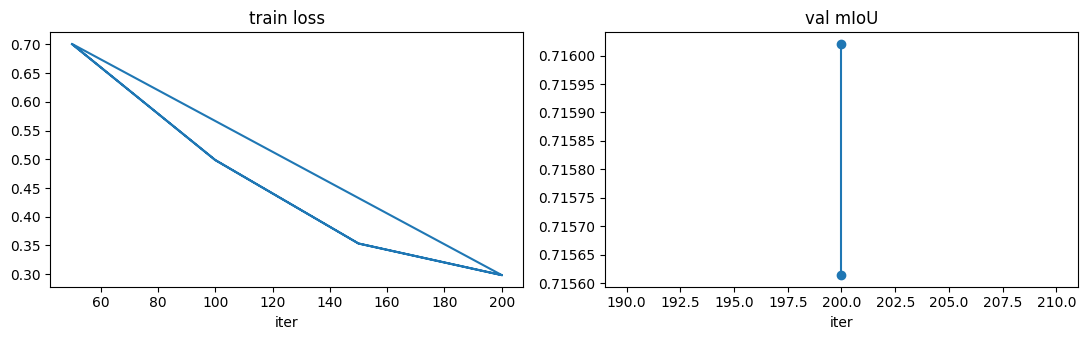

In [11]:
import matplotlib.pyplot as plt

if (work / "results.json").exists():
    print(json.dumps(json.load(open(work / "results.json")), indent=2))
else:
    print("chưa có results.json: train chưa đủ iter, sẽ có sau khi train tiếp xong")

recs = [json.loads(l) for l in open(work / "log.jsonl")]
train_recs = [r for r in recs if "loss" in r]
val_recs = [r for r in recs if r.get("split") == "val"]
if train_recs:
    print(f"tốc độ: {sum(r['sec_per_iter'] for r in train_recs[-5:]) / len(train_recs[-5:]):.3f} s/it "
          f"-> 160k iter ≈ {160000 * train_recs[-1]['sec_per_iter'] / 3600:.1f} giờ")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([r["iter"] for r in train_recs], [r["loss"] for r in train_recs]); ax[0].set_title("train loss")
if val_recs:
    ax[1].plot([r["iter"] for r in val_recs], [r["mIoU"] for r in val_recs], "o-"); ax[1].set_title("val mIoU")
for a in ax:
    a.set_xlabel("iter")
plt.tight_layout(); plt.show()

## 4b. Hiệu năng theo diện tích polyp (nhỏ / vừa / lớn)

`results.json` cộng dồn pixel trên cả tập nên bị polyp lớn chi phối và che lỗi ở polyp nhỏ. Mục này dự đoán lại từng ảnh bằng `best.pth` (test cùng miền + bộ chuyển miền), tính Dice, recall, precision, tỷ lệ diện tích dự đoán / thật theo từng ảnh, rồi chia theo diện tích polyp: **nhỏ** < 5% (cùng ngưỡng report mục 7.2), **vừa** 5–15%, **lớn** ≥ 15% diện tích ảnh.

Đọc biểu đồ:
- **Dice từng ảnh**: nhóm nào kém, phân tán bao nhiêu; ◆ là trung bình ± CI 95% (nhóm ít ảnh thì CI rộng, đừng đọc quá).
- **Recall / Precision**: recall thấp hơn là mô hình thiếu vùng / bỏ sót; precision thấp hơn là lấn ra / báo nhầm.
- **Dự đoán / thật**: > 1 là vẽ to hơn polyp, < 1 là vẽ nhỏ hơn; càng xa 1 càng lệch.
- **% ảnh hỏng** (Dice < 0.5), phần gạch chéo là bỏ sót hẳn (không pixel polyp nào được dự đoán).

Kết quả ở `outputs/segformer_b2/<RUN>/analysis/` (`perf_by_size.png`, `size_bins.csv`, `per_image.csv`, mặt nạ dự đoán `pred/`). Phải chạy trước bước dọn output vì bước đó xóa `data/processed`.

In [ ]:
# Dự đoán từng ảnh bằng best.pth và tính metric theo ảnh (results.json cộng dồn pixel cả tập nên không chia nhóm được).
# Mặt nạ dự đoán lưu ở analysis/pred/<dataset>/<tên>.png (vài MB) để về máy vẽ lại bằng scripts/analyze_errors.py --work-dir.
import cv2, numpy as np, pandas as pd, torch
from medseg.config import load_model_config
from medseg.data import build_dataloader
from medseg.models import build_segformer
from medseg.training import load_checkpoint, resolve_device

ana = work / "analysis"
used_path = work / "config_used.json"
used = json.load(open(used_path)) if used_path.exists() else {"dataset": DATASET, **load_model_config("segformer_b2")}
common = used["common"]
targets = [(DATASET, common["test_split"])]
cross = common.get("cross_domain")
if cross and cross["dataset"] != DATASET:
    targets.append((cross["dataset"], cross["split"]))

rows = []
ckpt = work / "best.pth"
if not ckpt.exists():
    print("chưa có best.pth: bỏ qua phân tích theo diện tích")
else:
    device = resolve_device(common["device"])
    model = build_segformer(used)
    it = load_checkpoint(ckpt, model, map_location="cpu")
    model.to(device).eval()
    print(f"best.pth ({it} iter) | preprocess {common.get('preprocess', 'none')}")
    for ds, split in targets:
        (ana / "pred" / ds).mkdir(parents=True, exist_ok=True)
        loader = build_dataloader(ds, split, batch_size=16, shuffle=False, num_workers=common["num_workers"],
                                  seed=common["seed"], image_size=common["image_size"], augment=common["augment"],
                                  normalize=common["normalize"], preprocess=common.get("preprocess", "none"))
        with torch.no_grad():
            for b in loader:
                preds = model.predict(b["image"].to(device)).cpu().numpy().astype(bool)
                gts = b["mask"][:, 0].numpy() > 0.5
                for name, p, g in zip(b["name"], preds, gts):
                    cv2.imwrite(str(ana / "pred" / ds / f"{name}.png"), p.astype(np.uint8) * 255)
                    tp, fp, fn = int((p & g).sum()), int((p & ~g).sum()), int((~p & g).sum())
                    rows.append({
                        "target": f"{ds}/{split}", "name": name, "gt_frac": float(g.mean()),
                        "tp": tp, "fp": fp, "fn": fn,
                        "dice": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.0,
                        "iou": tp / (tp + fp + fn) if (tp + fp + fn) else 1.0,
                        "recall": tp / (tp + fn) if (tp + fn) else float("nan"),
                        "precision": tp / (tp + fp) if (tp + fp) else float("nan"),
                        "area_ratio": (tp + fp) / (tp + fn) if (tp + fn) else float("nan"),  # dự đoán / thật
                    })
        print(f"  [{ds}/{split}] {sum(r['target'] == f'{ds}/{split}' for r in rows)} ảnh")

In [ ]:
# Hiệu năng theo diện tích polyp: nhỏ < 5% (như report mục 7.2), vừa 5–15%, lớn >= 15% diện tích ảnh 256 x 256
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

SIZE_BINS = (0.05, 0.15)
SIZE_LABELS = ("nhỏ", "vừa", "lớn")
FAIL_DICE = 0.5  # ảnh "hỏng"
COLORS = ("#2a78d6", "#eb6834")  # bảng màu đã kiểm tra mù màu
PRETTY = {"kvasir_seg": "Kvasir-SEG", "cvc_clinicdb": "CVC-ClinicDB"}

if rows:
    df = pd.DataFrame(rows)
    df["size_bin"] = pd.Categorical(np.select([df.gt_frac < SIZE_BINS[0], df.gt_frac < SIZE_BINS[1]], SIZE_LABELS[:2], SIZE_LABELS[2]),
                                    categories=SIZE_LABELS, ordered=True)
    tnames = list(dict.fromkeys(df.target))
    label = {t: f"{PRETTY.get(t.split('/')[0], t)} {t.split('/')[1]} ({'cùng miền' if t.startswith(DATASET) else 'chuyển miền'})" for t in tnames}

    def ci95(x, n=2000):
        x = np.asarray(x, float)
        m = x[np.random.default_rng(0).integers(0, len(x), (n, len(x)))].mean(1)
        return np.percentile(m, [2.5, 97.5])

    recs = []
    for (t, b), g in df.groupby(["target", "size_bin"], observed=True):
        lo, hi = ci95(g.dice)
        recs.append({"target": t, "size_bin": b, "n": len(g), "gt_frac_median": g.gt_frac.median(),
                     "dice_mean": g.dice.mean(), "dice_ci_lo": lo, "dice_ci_hi": hi, "dice_median": g.dice.median(),
                     "dice_pooled": 2 * g.tp.sum() / (2 * g.tp.sum() + g.fp.sum() + g.fn.sum()),
                     "iou_mean": g.iou.mean(), "recall_mean": g.recall.mean(), "precision_mean": g.precision.mean(),
                     "area_ratio_median": g.area_ratio.median(),
                     "over_seg_pct": 100 * (g.area_ratio > 1.25).mean(), "under_seg_pct": 100 * (g.area_ratio < 0.8).mean(),
                     "fail_pct": 100 * (g.dice < FAIL_DICE).mean(), "miss_pct": 100 * (g.tp == 0).mean()})
    tab = pd.DataFrame(recs)
    tab["target"] = pd.Categorical(tab.target, tnames, ordered=True)
    tab["size_bin"] = pd.Categorical(tab.size_bin, SIZE_LABELS, ordered=True)
    tab = tab.sort_values(["target", "size_bin"]).reset_index(drop=True)
    df.to_csv(ana / "per_image.csv", index=False)
    tab.to_csv(ana / "size_bins.csv", index=False)

    # ---- biểu đồ 2 x 2
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "axes.axisbelow": True, "grid.color": "#e6e5e0", "legend.frameon": False})
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    ax = ax.ravel()
    w = 0.8 / len(tnames)
    rng = np.random.default_rng(0)
    def xs(i):
        return np.arange(3) + (i - (len(tnames) - 1) / 2) * w
    def by_bin(t, col):
        return tab[tab.target == t].set_index("size_bin")[col].reindex(SIZE_LABELS).to_numpy(float)

    for i, t in enumerate(tnames):
        c = COLORS[i % len(COLORS)]
        for j, b in enumerate(SIZE_LABELS):
            g = df[(df.target == t) & (df.size_bin == b)]
            if g.empty:
                continue
            x = xs(i)[j]
            for k, (col, a, clip) in enumerate((("dice", ax[0], None), ("area_ratio", ax[2], (1 / 64, 64)))):
                v = g[col].dropna().to_numpy()
                if clip:
                    v = v.clip(*clip)
                a.boxplot(v, positions=[x], widths=w * 0.7, showfliers=False,
                          boxprops=dict(color=c, lw=1.2), medianprops=dict(color=c, lw=2),
                          whiskerprops=dict(color=c), capprops=dict(color=c))
                a.scatter(x + rng.uniform(-w * 0.28, w * 0.28, len(v)), v, s=9, color=c, alpha=0.45, lw=0, zorder=3)
        m, lo, hi = by_bin(t, "dice_mean"), by_bin(t, "dice_ci_lo"), by_bin(t, "dice_ci_hi")
        ax[0].errorbar(xs(i), m, yerr=[m - lo, hi - m], fmt="D", color="#0b0b0b", ms=5, capsize=3, lw=1, zorder=4)
        ax[1].plot(range(3), by_bin(t, "recall_mean"), "o-", color=c, lw=2, ms=7)
        ax[1].plot(range(3), by_bin(t, "precision_mean"), "s--", color=c, lw=2, ms=6)
        ax[3].bar(xs(i), by_bin(t, "fail_pct"), w - 0.04, color=c)
        ax[3].bar(xs(i), by_bin(t, "miss_pct"), w - 0.04, color="none", edgecolor="#0b0b0b", hatch="///", lw=0)
        for x, v in zip(xs(i), by_bin(t, "fail_pct")):
            if not np.isnan(v):
                ax[3].annotate(f"{v:.0f}%", (x, v), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)

    ax[0].set(title="Dice từng ảnh (◆ trung bình ± CI 95%)", ylabel="Dice", ylim=(-0.03, 1.03))
    ax[1].set(title="Recall và Precision", ylabel="trung bình theo ảnh", ylim=(0, 1.05))
    ax[1].legend(handles=[Line2D([], [], color="#52514e", marker="o", lw=2, label="recall: bắt được bao nhiêu % polyp"),
                          Line2D([], [], color="#52514e", marker="s", ls="--", lw=2, label="precision: dự đoán đúng bao nhiêu %")],
                 loc="lower right", fontsize=9)
    ax[2].axhline(1, color="#0b0b0b", lw=1, ls="--")
    ax[2].set_yscale("log")
    ax[2].set_yticks([1 / 8, 1 / 4, 1 / 2, 1, 2, 4, 8], ["1/8", "1/4", "1/2", "1", "2", "4", "8"])
    ax[2].set(title="Lệch diện tích: dự đoán / thật (>1 lấn ra, <1 thiếu)", ylabel="tỷ lệ (log)", ylim=(1 / 12, 12))
    ax[3].set(title=f"% ảnh hỏng (Dice < {FAIL_DICE}); gạch chéo: bỏ sót hẳn (TP = 0)", ylabel="% ảnh trong nhóm",
              ylim=(0, max(10, float(tab.fail_pct.max()) * 1.25)))
    edges = [f"<{SIZE_BINS[0]:.0%}", f"{SIZE_BINS[0]:.0%}–{SIZE_BINS[1]:.0%}", f"≥{SIZE_BINS[1]:.0%}"]
    ns = ["/".join(str(int(tab[(tab.target == t) & (tab.size_bin == b)].n.sum())) for t in tnames) for b in SIZE_LABELS]
    for a in ax:
        a.set_xticks(range(3), [f"{b}\n{e}\nn={n}" for b, e, n in zip(SIZE_LABELS, edges, ns)])
        a.set_xlim(-0.5, 2.5)
        a.grid(axis="x", visible=False)
    fig.legend(handles=[Patch(color=COLORS[i % len(COLORS)], label=label[t]) for i, t in enumerate(tnames)],
               loc="upper center", ncol=len(tnames), bbox_to_anchor=(0.5, 1.0))
    fig.suptitle("Hiệu năng theo diện tích polyp (tỷ lệ diện tích polyp / ảnh)", y=1.04, fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(ana / "perf_by_size.png", dpi=130, bbox_inches="tight")
    plt.show()

    # ---- bảng + nhận xét tự động
    show = ["target", "size_bin", "n", "dice_mean", "dice_pooled", "recall_mean", "precision_mean",
            "area_ratio_median", "over_seg_pct", "under_seg_pct", "fail_pct", "miss_pct"]
    print(tab[show].round(3).to_string(index=False))
    for t in tnames:
        g = tab[tab.target == t].set_index("size_bin")
        d = df[df.target == t]
        pooled = 2 * d.tp.sum() / (2 * d.tp.sum() + d.fp.sum() + d.fn.sum())
        print(f"\n[{label[t]}] Dice TB theo ảnh {d.dice.mean():.3f} | Dice cộng dồn pixel (như results.json) {pooled:.3f}")
        if {"nhỏ", "lớn"} <= set(g.index):
            print(f"  nhỏ so với lớn: Dice {g.loc['nhỏ', 'dice_mean']:.3f} vs {g.loc['lớn', 'dice_mean']:.3f} "
                  f"(chênh {g.loc['lớn', 'dice_mean'] - g.loc['nhỏ', 'dice_mean']:+.3f})")
        for b, r in g.iterrows():
            lean = "thiên về thiếu vùng / bỏ sót (recall < precision)" if r.recall_mean < r.precision_mean else "thiên về lấn ra (precision < recall)"
            print(f"  {b}: {lean}; dự đoán/thật trung vị {r.area_ratio_median:.2f}; hỏng {r.fail_pct:.0f}%, bỏ sót hẳn {r.miss_pct:.0f}%")
        worst = d.nsmallest(5, "dice")
        print("  5 ảnh tệ nhất:", ", ".join(f"{n} (Dice {v:.2f}, {a:.1%})" for n, v, a in zip(worst.name, worst.dice, worst.gt_frac)))
    print("\nbảng:", ana / "size_bins.csv", "|", ana / "per_image.csv")

### 4c. Ví dụ: 5 dự đoán tốt nhất và 5 kém nhất

Với mỗi tập đánh giá, xếp ảnh theo Dice rồi vẽ 5 ảnh cao nhất và 5 ảnh thấp nhất, mỗi ảnh 3 hàng: ảnh gốc, nhãn thật (vàng), dự đoán (xanh lá: đúng, đỏ: dự đoán thừa, xanh dương: bỏ sót). Tiêu đề ghi Dice, nhóm diện tích và tỷ lệ diện tích polyp; dưới cùng là tỷ lệ diện tích dự đoán / thật. Hình lưu ở `analysis/best5_<dataset>.png`, `analysis/worst5_<dataset>.png`.

In [ ]:
# 5 dự đoán tốt nhất và 5 kém nhất của mỗi tập (xếp theo Dice từng ảnh): ảnh | nhãn thật | dự đoán
from medseg.config import load_data_config
from medseg.data.dataset import processed_root

N_SHOW = 5
GT_C = np.array((237, 161, 0))  # nhãn thật
TP_C, FP_C, FN_C = np.array((27, 175, 122)), np.array((227, 73, 72)), np.array((42, 120, 214))  # đúng, thừa, bỏ sót


def tint(img, layers, alpha=0.5):
    out = img.astype(np.float32)
    for m, c in layers:
        out[m] = (1 - alpha) * out[m] + alpha * c
    return out.clip(0, 255).astype(np.uint8)


def show_cases(t, picks, title, fname):
    ds = t.split("/")[0]
    root = processed_root(ds, common["image_size"], load_data_config()["processed_dir"], common.get("preprocess", "none"))
    fig, axes = plt.subplots(3, len(picks), figsize=(2.9 * len(picks), 9.4), squeeze=False)
    for j, (_, r) in enumerate(picks.iterrows()):
        img = cv2.cvtColor(cv2.imread(str(root / "images" / f"{r['name']}.png")), cv2.COLOR_BGR2RGB)
        gt = cv2.imread(str(root / "masks" / f"{r['name']}.png"), cv2.IMREAD_GRAYSCALE) > 127
        pr = cv2.imread(str(ana / "pred" / ds / f"{r['name']}.png"), cv2.IMREAD_GRAYSCALE) > 127
        panels = (img, tint(img, [(gt, GT_C)]), tint(img, [(pr & gt, TP_C), (pr & ~gt, FP_C), (~pr & gt, FN_C)]))
        for i, p in enumerate(panels):
            a = axes[i, j]
            a.imshow(p)
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
            for s in a.spines.values():
                s.set_visible(False)
        axes[0, j].set_title(f"{r['name'][:16]}\nDice {r.dice:.3f} · {r.size_bin} ({r.gt_frac:.1%})", fontsize=9)
        axes[2, j].set_xlabel(f"dự đoán/thật {r.area_ratio:.2f}", fontsize=8.5)
    for i, lab in enumerate(("ảnh", "nhãn thật", "dự đoán")):
        axes[i, 0].set_ylabel(lab, fontsize=10)
    fig.legend(handles=[Patch(color=GT_C / 255, label="nhãn thật"), Patch(color=TP_C / 255, label="đúng (TP)"),
                        Patch(color=FP_C / 255, label="dự đoán thừa (FP)"), Patch(color=FN_C / 255, label="bỏ sót (FN)")],
               loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0), fontsize=9)
    fig.suptitle(title, y=1.04, fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(ana / fname, dpi=110, bbox_inches="tight")
    plt.show()


if rows:
    for t in tnames:
        d = df[df.target == t]
        ds = t.split("/")[0]
        show_cases(t, d.nlargest(N_SHOW, "dice"), f"{N_SHOW} dự đoán tốt nhất — {label[t]}", f"best{N_SHOW}_{ds}.png")
        show_cases(t, d.nsmallest(N_SHOW, "dice"), f"{N_SHOW} dự đoán kém nhất — {label[t]}", f"worst{N_SHOW}_{ds}.png")
    print("hình:", ", ".join(p.name for p in sorted(ana.glob(f"*{N_SHOW}_*.png"))))

In [ ]:
# (Tùy chọn) Hình phụ: kiểu lỗi theo diện tích, Dice theo đặc điểm dữ liệu, ảnh tệ nhất.
# Cần gói code build lại có scripts/analyze_errors.py; dùng mặt nạ dự đoán ở trên, không dự đoán lại.
from IPython.display import Image, display

script = ROOT / "scripts/analyze_errors.py"
if not rows:
    print("chưa có dự đoán: bỏ qua")
elif not script.exists():
    print("gói code chưa có scripts/analyze_errors.py: bỏ qua hình phụ. Build lại gói (python scripts/build_kaggle.py) "
          f"hoặc tải {ana.relative_to(ROOT)}/pred về máy rồi chạy: python scripts/analyze_errors.py --work-dir {work.relative_to(ROOT)}")
else:
    r = subprocess.run([sys.executable, "-u", str(script), "--work-dir", str(work.relative_to(ROOT))],
                       capture_output=True, text=True)
    print(r.stdout[-4000:], r.stderr[-3000:] if r.returncode else "")
    r.check_returncode()
    for f in ["perf_by_size.png", "error_types.png", "dice_vs_area.png", "error_factors.png", *sorted(p.name for p in ana.glob("worst_*.png"))]:
        display(Image(str(ana / f)))

## 5. Dọn output (giới hạn 20 GB của /kaggle/working)

In [12]:
if DELETE_ITER_CKPTS:
    for p in work.glob("iter_*.pth"):
        p.unlink()
shutil.rmtree(ROOT / "data/processed", ignore_errors=True)  # tạo lại được ở bước 2
for p in sorted(work.iterdir()):
    print(f"{p.stat().st_size / 1e6:9.1f} MB  {p.name}")

    328.6 MB  best.pth
      0.0 MB  config_used.json
    328.7 MB  latest.pth
      0.0 MB  log.jsonl
      0.0 MB  results.json
